In [ ]:
# Mount Google Drive and Set Paths
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Setup and load

import pandas as pd
import numpy as np
from pathlib import Path
import joblib

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

base_dir = Path("/content/drive/MyDrive/gdsc-drug-response")
data_path = base_dir / "processed" / "cisplatin_rnaseq_modelready_clean.csv"
df = pd.read_csv(data_path)

df.shape
df.head()

,model_id,drug_name,ln_ic50,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A2ML1-AS1,...,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11AP1,ZYG11B,ZYX,ZZEF1,ZZZ3
0,SIDM01132,Cisplatin,3.168266,5.18545,2.9833,0.0000,0.52325,0.0000,0.0213,0.0,...,6.17065,0.31285,1.60475,3.10825,0.6801,0.0,2.58955,5.95435,3.47415,4.0301
1,SIDM00848,Cisplatin,-0.007561,4.86890,3.4476,0.0000,1.99640,0.1243,3.1890,0.0,...,7.09150,1.68260,2.33060,5.18630,0.0841,0.0,3.09930,5.52420,3.60640,4.5211
2,SIDM00269,Cisplatin,0.045420,4.54970,3.8001,0.0841,3.21570,0.0566,0.5753,0.0,...,4.53920,2.82980,3.41280,6.78270,2.3190,0.0,4.21410,9.01050,4.93400,5.4561
3,SIDM00203,Cisplatin,0.923136,4.22500,3.2095,0.0144,0.50590,0.0976,2.8156,0.0,...,6.45100,2.49570,3.47640,5.30710,3.0321,0.0,4.47310,6.95290,4.35900,5.3366
4,SIDM01111,Cisplatin,-0.134330,4.49250,2.8115,0.0144,0.47510,0.0286,0.5558,0.0,...,7.37920,1.28690,2.26000,4.94810,2.7634,0.0,3.20950,3.99550,4.02240,4.9635


In [ ]:
# Define columns:

model_col    = "model_id"
drug_col     = "drug_name"
response_col = "ln_ic50"

non_feature_cols = [model_col, drug_col, response_col]
feature_cols = [c for c in df.columns if c not in non_feature_cols]

X = df[feature_cols].values
y = df[response_col].values

X.shape, y.shape

((743, 36438), (743,))

In [ ]:
#  Train/test split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

X_train.shape, X_test.shape

((594, 36438), (149, 36438))

In [ ]:
ridge_a100 = make_pipeline(
    SimpleImputer(strategy="mean"),
    StandardScaler(),
    Ridge(alpha=100, random_state=42)
)

ridge_a10000 = make_pipeline(
    SimpleImputer(strategy="mean"),
    StandardScaler(),
    Ridge(alpha=10000, random_state=42)
)

rf3 = make_pipeline(
    SimpleImputer(strategy="mean"),
    RandomForestRegressor(
        n_estimators=300,
        max_depth=7,
        max_features=200,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    )
)

ridge_a100.fit(X_train, y_train)
ridge_a10000.fit(X_train, y_train)
rf3.fit(X_train, y_train)

Pipeline(steps=[('simpleimputer', SimpleImputer()),
                ('randomforestregressor',
                 RandomForestRegressor(max_depth=7, max_features=200,
                                       min_samples_leaf=5, n_estimators=300,
                                       n_jobs=-1, random_state=42))])

In [ ]:
def regression_metrics(y_true, y_pred):
    r2   = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    return r2, rmse, mae

In [ ]:
# Build the metrics table

def get_metrics(name, model):
    y_train_pred = model.predict(X_train)
    y_test_pred  = model.predict(X_test)
    r2_train, rmse_train, mae_train = regression_metrics(y_train, y_train_pred)
    r2_test,  rmse_test,  mae_test  = regression_metrics(y_test,  y_test_pred)
    return {
        "model": name,
        "r2_train": r2_train,
        "r2_test": r2_test,
        "rmse_train": rmse_train,
        "rmse_test": rmse_test,
        "mae_train": mae_train,
        "mae_test": mae_test
    }

rows = [
    get_metrics("Ridge_a100",   ridge_a100),
    get_metrics("Ridge_a10000", ridge_a10000),
    get_metrics("RF3",          rf3),
]

metrics_df = pd.DataFrame(rows)
metrics_df

,model,r2_train,r2_test,rmse_train,rmse_test,mae_train,mae_test
0,Ridge_a100,0.999973,0.316966,0.009482,1.555581,0.006265,1.231734
1,Ridge_a10000,0.932001,0.339243,0.477268,1.530003,0.353436,1.222917
2,RF3,0.763314,0.278504,0.890428,1.598778,0.684118,1.267228


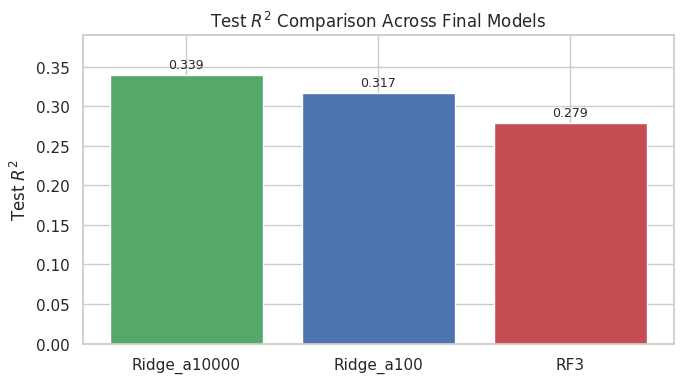

In [ ]:
fig_dir = base_dir / "figures"
fig_dir.mkdir(exist_ok=True)

plot_df = metrics_df.sort_values("r2_test", ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(plot_df["model"], plot_df["r2_test"], color=["#55A868", "#4C72B0", "#C44E52"])

ax.set_ylabel("Test $R^2$")
ax.set_title("Test $R^2$ Comparison Across Final Models")
ax.set_ylim(0, plot_df["r2_test"].max() + 0.05)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height + 0.005, f"{height:.3f}",
             ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(fig_dir / "model_test_r2_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

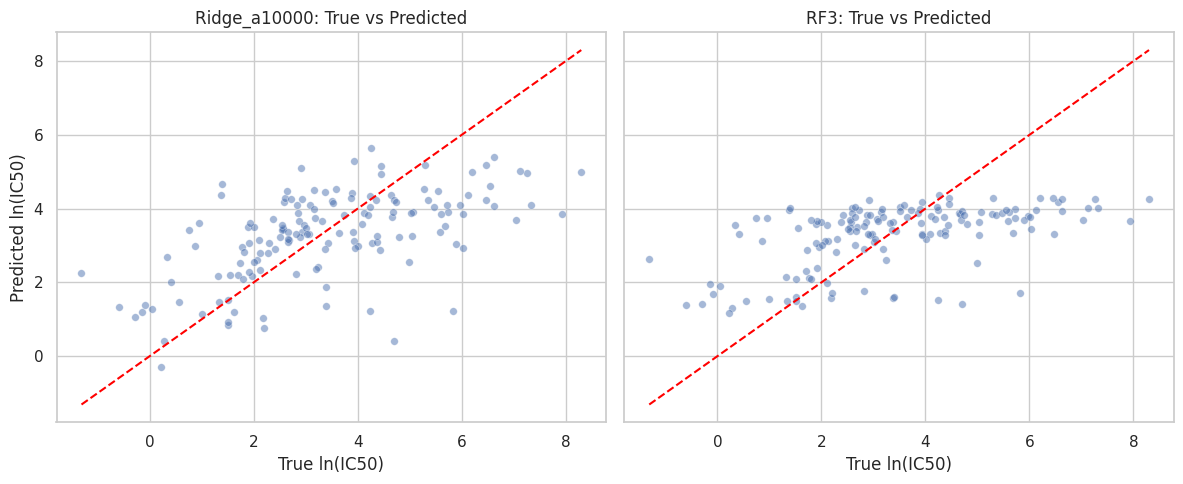

In [ ]:
# Get predictions
ridge_preds = ridge_a10000.predict(X_test)
rf3_preds = rf3.predict(X_test)

# Build a small plotting dataframe
plot_df = pd.DataFrame({
    "true": y_test,
    "Ridge_a10000": ridge_preds,
    "RF3": rf3_preds
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

# Common limits so both plots use the same scale
min_val = min(plot_df["true"].min(), plot_df["Ridge_a10000"].min(), plot_df["RF3"].min())
max_val = max(plot_df["true"].max(), plot_df["Ridge_a10000"].max(), plot_df["RF3"].max())

# Ridge plot
sns.scatterplot(
    x="true",
    y="Ridge_a10000",
    data=plot_df,
    alpha=0.5,
    s=30,
    ax=axes[0]
)
axes[0].plot([min_val, max_val], [min_val, max_val], "--", color="red")
axes[0].set_title("Ridge_a10000: True vs Predicted")
axes[0].set_xlabel("True ln(IC50)")
axes[0].set_ylabel("Predicted ln(IC50)")

# RF plot
sns.scatterplot(
    x="true",
    y="RF3",
    data=plot_df,
    alpha=0.5,
    s=30,
    ax=axes[1]
)
axes[1].plot([min_val, max_val], [min_val, max_val], "--", color="red")
axes[1].set_title("RF3: True vs Predicted")
axes[1].set_xlabel("True ln(IC50)")
axes[1].set_ylabel("Predicted ln(IC50)")

plt.tight_layout()
plt.savefig(fig_dir / "predicted_vs_true_ridge_rf.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

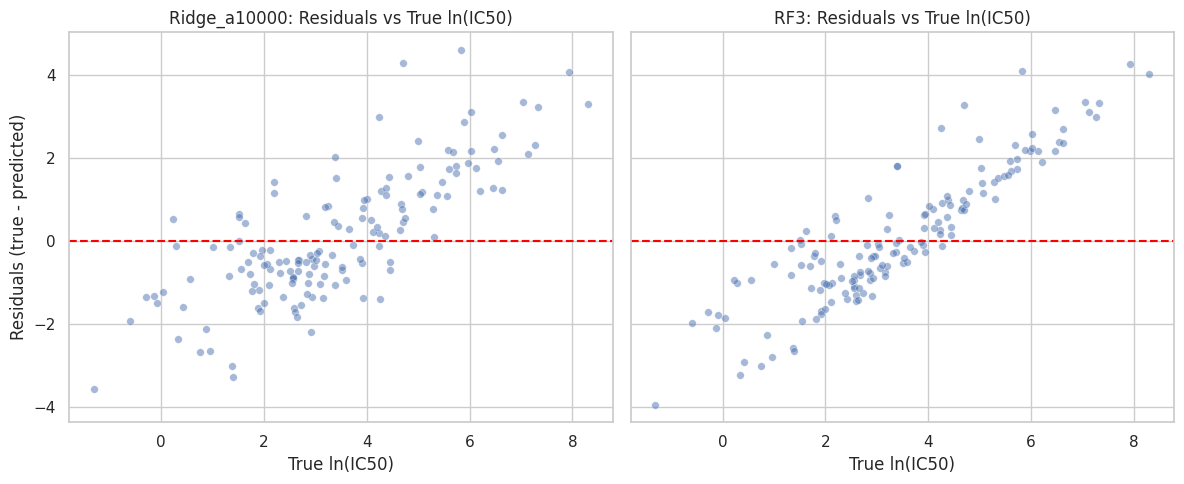

In [ ]:
# Predictions on the test set
ridge_preds = ridge_a10000.predict(X_test)
rf3_preds = rf3.predict(X_test)

# Residuals = true - predicted
ridge_resid = y_test - ridge_preds
rf3_resid = y_test - rf3_preds

# Data for plotting
resid_df = pd.DataFrame({
    "true": y_test,
    "Ridge_a10000_resid": ridge_resid,
    "RF3_resid": rf3_resid
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Ridge residual plot
sns.scatterplot(
    x="true",
    y="Ridge_a10000_resid",
    data=resid_df,
    alpha=0.5,
    s=30,
    ax=axes[0]
)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Ridge_a10000: Residuals vs True ln(IC50)")
axes[0].set_xlabel("True ln(IC50)")
axes[0].set_ylabel("Residuals (true - predicted)")

# RF residual plot
sns.scatterplot(
    x="true",
    y="RF3_resid",
    data=resid_df,
    alpha=0.5,
    s=30,
    ax=axes[1]
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("RF3: Residuals vs True ln(IC50)")
axes[1].set_xlabel("True ln(IC50)")
axes[1].set_ylabel("Residuals (true - predicted)")

plt.tight_layout()
plt.savefig(fig_dir / "residuals_vs_true_ridge_rf.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

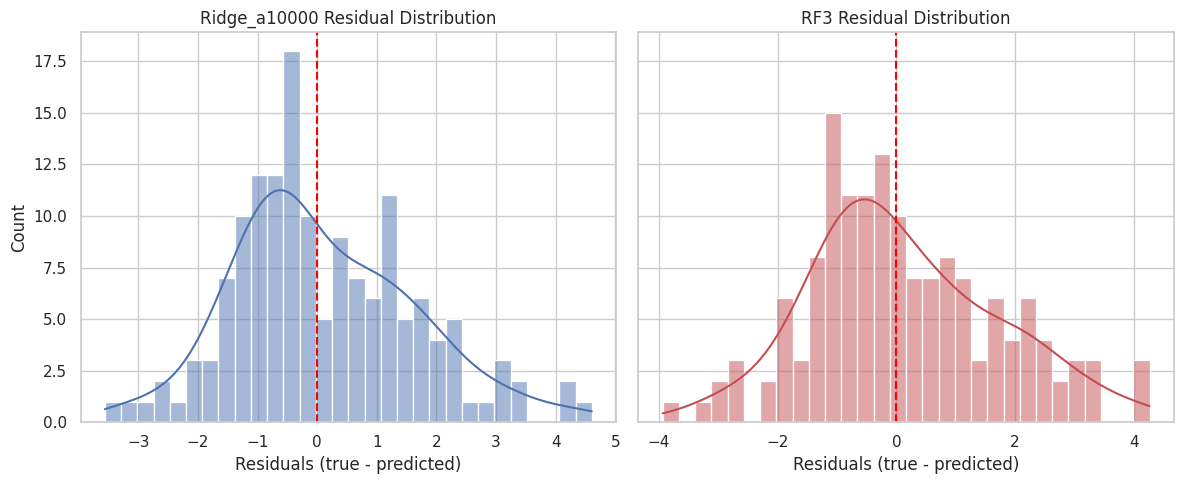

In [ ]:
# Predictions on the test set
ridge_preds = ridge_a10000.predict(X_test)
rf3_preds = rf3.predict(X_test)

# Residuals = true - predicted
ridge_resid = y_test - ridge_preds
rf3_resid = y_test - rf3_preds

resid_df = pd.DataFrame({
    "Ridge_a10000_resid": ridge_resid,
    "RF3_resid": rf3_resid
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

sns.histplot(resid_df["Ridge_a10000_resid"], bins=30, kde=True, ax=axes[0], color="#4C72B0")
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title("Ridge_a10000 Residual Distribution")
axes[0].set_xlabel("Residuals (true - predicted)")
axes[0].set_ylabel("Count")

sns.histplot(resid_df["RF3_resid"], bins=30, kde=True, ax=axes[1], color="#C44E52")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("RF3 Residual Distribution")
axes[1].set_xlabel("Residuals (true - predicted)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.savefig(fig_dir / "residual_distribution_ridge_rf.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

/tmp/ipykernel_736/1551415376.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_coef_df, x="coef", y="gene", palette="viridis")


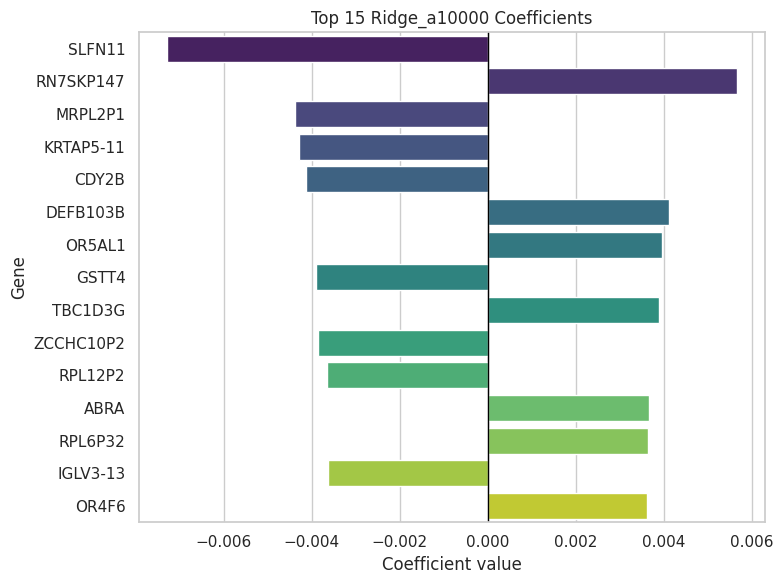

In [ ]:
# Ridge feature importance / coefficient plot

gene_names = df.drop(columns=["model_id", "drug_name", "ln_ic50"]).columns

ridge_a10000.fit(X_train, y_train)

coef_df = pd.DataFrame({
    "gene": gene_names,
    "coef": ridge_a10000.named_steps["ridge"].coef_
})

top_n = 15
top_coef_df = coef_df.reindex(coef_df["coef"].abs().sort_values(ascending=False).index).head(top_n)

plt.figure(figsize=(8, 6))
sns.barplot(data=top_coef_df, x="coef", y="gene", palette="viridis")
plt.axvline(0, color="black", linewidth=1)
plt.title(f"Top {top_n} Ridge_a10000 Coefficients")
plt.xlabel("Coefficient value")
plt.ylabel("Gene")
plt.tight_layout()
plt.savefig(fig_dir / "ridge_a10000_top_coefficients.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

/tmp/ipykernel_736/272869429.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_rf_df, x="importance", y="gene", palette="magma")


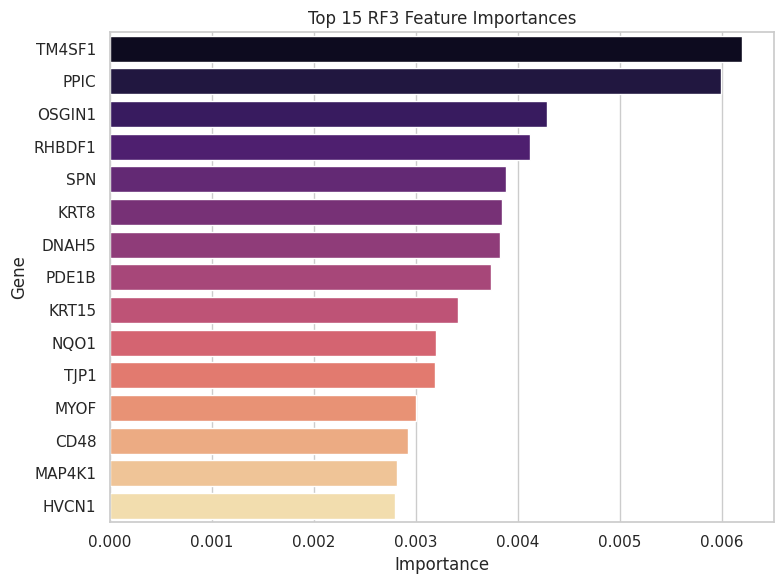

In [ ]:
# RF3 feature importance / coefficient plot

gene_names = df.drop(columns=["model_id", "drug_name", "ln_ic50"]).columns

rf_importance_df = pd.DataFrame({
    "gene": gene_names,
    "importance": rf3.named_steps["randomforestregressor"].feature_importances_
})

top_n = 15
top_rf_df = rf_importance_df.sort_values("importance", ascending=False).head(top_n)

plt.figure(figsize=(8, 6))
sns.barplot(data=top_rf_df, x="importance", y="gene", palette="magma")
plt.title(f"Top {top_n} RF3 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Gene")
plt.tight_layout()
plt.savefig(fig_dir / "rf3_top_feature_importances.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

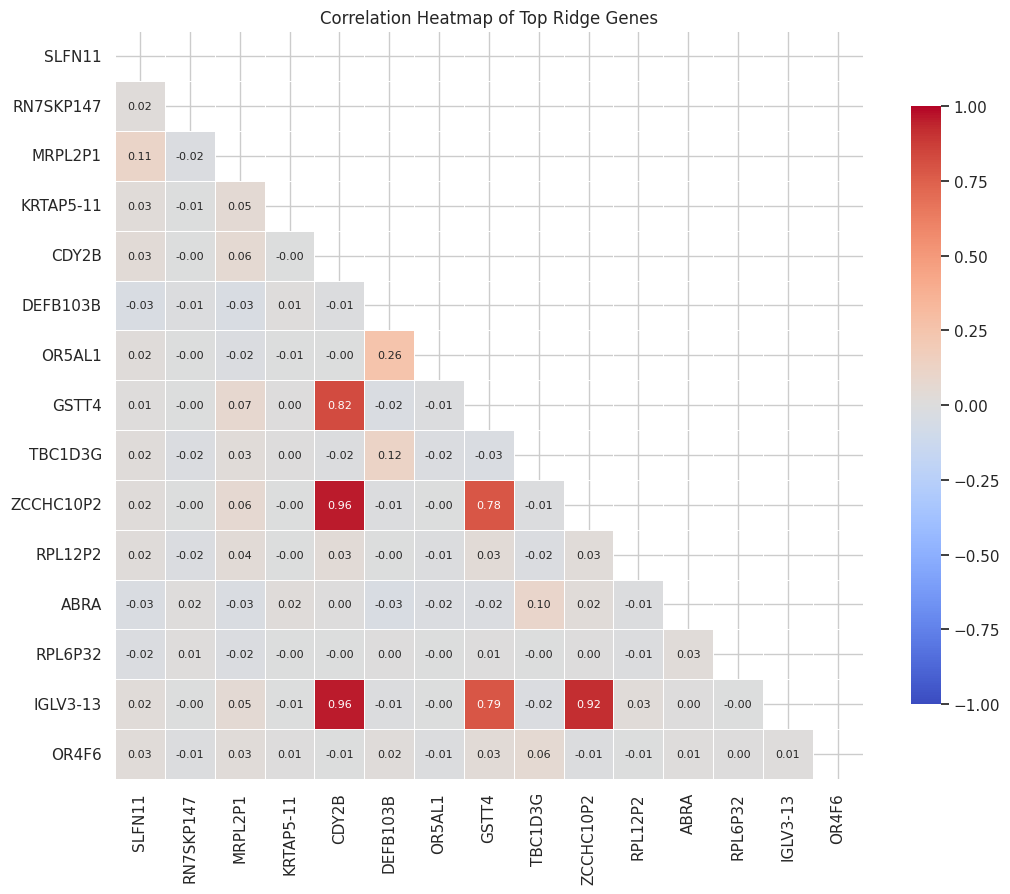

In [ ]:
# Sort top genes by absolute Ridge coefficient, then take their names
top_genes_sorted = (
    coef_df.reindex(coef_df["coef"].abs().sort_values(ascending=False).index)
    .head(15)["gene"]
    .tolist()
)

gene_df = df[top_genes_sorted]
corr = gene_df.corr()

# Mask upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(11, 9))
sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": 8},
    cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Heatmap of Top Ridge Genes")
plt.tight_layout()
plt.savefig(fig_dir / "top_gene_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

In [ ]:
save_dir = Path("/content/drive/MyDrive/gdsc-drug-response/notebook_artifacts")
save_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(X_train, save_dir / "X_train.pkl")
joblib.dump(X_test, save_dir / "X_test.pkl")
joblib.dump(y_train, save_dir / "y_train.pkl")
joblib.dump(y_test, save_dir / "y_test.pkl")

joblib.dump(ridge_a10000, save_dir / "ridge_a10000.pkl")
joblib.dump(rf3, save_dir / "rf3.pkl")

# use a separate feature-name variable instead of X.columns
joblib.dump(feature_cols, save_dir / "feature_names.pkl")

['/content/drive/MyDrive/gdsc-drug-response/notebook_artifacts/feature_names.pkl']